# Team M.A.E.L goal is to create an end-to-end system that automatically processes, categorizes, and extracts insights from news articles from a specific dataset.
# The project will require the team to actively  integrate multiple NLP techniques into a cohesive, working system.
# The goal is to use the coding as a tool to solve real-world problems and build our analytical and systyem design skills.
# Team M.A.E.L has picked BC News Classification dataset from Kaggle.

In [1]:
# Install Kaggle
!pip install kaggle --quiet

In [2]:
from google.colab import files
import zipfile
import io

# Upload the BBC News dataset ZIP
uploaded = files.upload()

# Extract the uploaded ZIP file
for filename, file_data in uploaded.items():
    if filename.lower().endswith(".zip"):
        with zipfile.ZipFile(io.BytesIO(file_data), "r") as zip_ref:
            zip_ref.extractall("/content")

        print("Dataset extracted successfully:", filename)

Saving learn-ai-bbc.zip to learn-ai-bbc.zip
Dataset extracted successfully: learn-ai-bbc.zip



## Module 1: Business Application - BBC News Automated Content Categorization

### Business Case
Digital media publishers like BBC handle thousands of articles across politics, business,
entertainment, sports, and technology. Manual categorization is slow, expensive, and prone to human error.
Automating document classification and feature extraction accelerates content routing, metadata tagging,
and personalized user recommendations.

### Target Users
- Editors and Digital Publishers automating article tagging and archival.
- Content Strategists tracking publishing trends across verticals.
- Recommendation Engine Developers delivering category-specific news feeds.

### Value Proposition
Reduces content processing overhead by automatically assigning articles to core news categories,
extracting key syntactic features, mapping entities, and monitoring domain-specific language trends.


In [3]:
# ==========================================
# MODULE 1: BUSINESS APPLICATION
# ==========================================


import re
import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import spacy
from spacy import displacy

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

from nltk.sentiment import SentimentIntensityAnalyzer
import nltk

nltk.download('vader_lexicon', quiet=True)
nlp = spacy.load("en_core_web_sm")

# Automatically unzip learn-ai-bbc.zip if BBC News Train.csv is not present
zip_path = '/content/learn-ai-bbc.zip'
csv_path = 'BBC News Train.csv'

if not os.path.exists(csv_path) and os.path.exists(zip_path):
    print(f"Extracting {zip_path}...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('.')

# Load BBC Dataset
df = pd.read_csv(csv_path)

# Standardize columns for pipeline
df['text'] = df['Text']
df['category'] = df['Category']

print(f"Dataset Loaded Successfully! Shape: {df.shape}")
print("Category Distribution:\n", df['category'].value_counts())


Dataset Loaded Successfully! Shape: (1490, 5)
Category Distribution:
 category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64


## Module 2: Text Preprocessing

In this module, we clean and prepare the news articles for NLP analysis.

We remove unnecessary characters, URLs, and HTML tags. We also use spaCy for tokenization, lemmatization, and stopword removal.

The purpose is to make the text more consistent before feature extraction and machine learning.

In [4]:

# ==========================================
# MODULE 2: TEXT PREPROCESSING (Handling Edge Cases)
# ==========================================
print("\n--- Module 2: Text Preprocessing & Edge Cases ---")

def preprocess_text(text):
    # Edge case 1: Non-string, Empty, or NaN inputs
    if not isinstance(text, str) or not text.strip():
        return ""

    # Edge case 2: Remove URLs and HTML tags
    text = re.sub(r'http\S+|www\S+|<.*?>', '', text)

    # Edge case 3: Remove non-alphabetical characters (numbers, special symbols, non-ASCII)
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Process with spaCy for lowercasing, lemmatization, and stop-word removal
    doc = nlp(text.lower())
    tokens = [token.lemma_ for token in doc if not token.is_stop and len(token.lemma_) > 2]

    return " ".join(tokens)

# Demonstrate Handling Edge Cases
edge_cases = ["", "   ", None, "Check https://bbc.co.uk/news!", "Headline: $100M revenue boost in 2024!!!"]
print("\nEdge Case Testing:")
for ec in edge_cases:
    print(f"Input:  '{ec}'\nResult: '{preprocess_text(ec)}'\n")

# Faster preprocessing using spaCy batches
print("Preprocessing dataset...")

cleaned_texts = []

for doc in nlp.pipe(
    df['text'].fillna('').astype(str).str.lower(),
    batch_size=64,
    disable=['parser', 'ner']
):
    tokens = [
        token.lemma_
        for token in doc
        if token.is_alpha
        and not token.is_stop
        and len(token.lemma_) > 2
    ]
    cleaned_texts.append(" ".join(tokens))

df['cleaned_text'] = cleaned_texts

print("Preprocessing complete!")



--- Module 2: Text Preprocessing & Edge Cases ---

Edge Case Testing:
Input:  ''
Result: ''

Input:  '   '
Result: ''

Input:  'None'
Result: ''

Input:  'Check https://bbc.co.uk/news!'
Result: 'check'

Input:  'Headline: $100M revenue boost in 2024!!!'
Result: 'headline revenue boost'

Preprocessing dataset...
Preprocessing complete!


## TF-IDF (Parameters, Words by Category, Visualization)


--- Module 3: TF-IDF Analysis ---
Unigram Vocabulary Sample: ['abandon' 'abbas' 'abc' 'aberdeen' 'abide' 'ability' 'able' 'abolish'
 'abroad' 'absa']
Bigram Vocabulary Sample:  ['abandon' 'abbas' 'abc' 'abide' 'ability' 'able' 'abolish' 'abroad'
 'absence' 'absolute']

Top TF-IDF Words per Category:
  BUSINESS: [('say', np.float64(0.0635)), ('firm', np.float64(0.0476)), ('company', np.float64(0.0456)), ('market', np.float64(0.0432)), ('year', np.float64(0.0415))]
  TECH: [('mobile', np.float64(0.0613)), ('say', np.float64(0.0548)), ('phone', np.float64(0.0538)), ('people', np.float64(0.0534)), ('technology', np.float64(0.0477))]
  POLITICS: [('say', np.float64(0.0885)), ('labour', np.float64(0.0769)), ('election', np.float64(0.075)), ('blair', np.float64(0.0668)), ('party', np.float64(0.0638))]
  SPORT: [('win', np.float64(0.0643)), ('game', np.float64(0.0552)), ('play', np.float64(0.048)), ('england', np.float64(0.0461)), ('say', np.float64(0.0418))]
  ENTERTAINMENT: [('film', np.flo

/tmp/ipykernel_5189/1292831649.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=scores, y=words, palette='viridis')


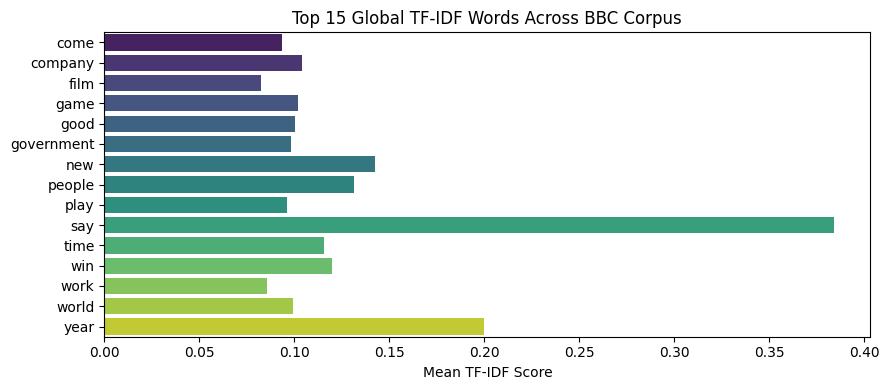

In [5]:

# ==========================================
# MODULE 3: TF-IDF (Parameters, Words by Category, Visualization)
# ==========================================
print("\n--- Module 3: TF-IDF Analysis ---")

# 1. Parameter Comparison (Unigrams vs Bigrams, sublinear TF scaling)
vectorizer_uni = TfidfVectorizer(ngram_range=(1,1), max_features=5000, stop_words='english')
vectorizer_bi  = TfidfVectorizer(ngram_range=(1,2), max_features=5000, sublinear_tf=True, stop_words='english')

tfidf_uni = vectorizer_uni.fit_transform(df['cleaned_text'])
tfidf_bi  = vectorizer_bi.fit_transform(df['cleaned_text'])

print("Unigram Vocabulary Sample:", vectorizer_uni.get_feature_names_out()[:10])
print("Bigram Vocabulary Sample: ", vectorizer_bi.get_feature_names_out()[:10])

# 2. Top Important Terms by BBC News Category
def top_words_by_category(df, text_col, cat_col, top_n=5):
    vec = TfidfVectorizer(max_features=2000)
    X = vec.fit_transform(df[text_col])
    features = np.array(vec.get_feature_names_out())

    results = {}
    for cat in df[cat_col].unique():
        cat_indices = df[df[cat_col] == cat].index
        mean_tfidf = X[cat_indices].mean(axis=0).A1
        top_idx = mean_tfidf.argsort()[::-1][:top_n]
        results[cat] = list(zip(features[top_idx], np.round(mean_tfidf[top_idx], 4)))
    return results

top_category_terms = top_words_by_category(df, 'cleaned_text', 'category')
print("\nTop TF-IDF Words per Category:")
for cat, words in top_category_terms.items():
    print(f"  {cat.upper()}: {words}")

# 3. Global Feature Importance Visualization
vec_global = TfidfVectorizer(max_features=15, stop_words='english')
X_global = vec_global.fit_transform(df['cleaned_text'])
scores = X_global.mean(axis=0).A1
words = vec_global.get_feature_names_out()

plt.figure(figsize=(9, 4))
sns.barplot(x=scores, y=words, palette='viridis')
plt.title("Top 15 Global TF-IDF Words Across BBC Corpus")
plt.xlabel("Mean TF-IDF Score")
plt.tight_layout()
plt.show()


### TF-IDF Feature Analysis

In this module, we used TF-IDF to convert the news articles into numerical features that machine learning models can understand.

We explored unigrams and bigrams to see how individual words and two-word combinations represent the articles. Unigrams help identify important words, while bigrams can preserve more information about the context.

We also analyzed important terms across different news categories. This helped us understand how the vocabulary of Business, Politics, Sports, Technology, and Entertainment articles can differ.

TF-IDF is useful for news classification because it gives more weight to words that help distinguish articles. However, it does not fully understand sentence meaning or word relationships.

## POS Tagging (Distributions & Writing Styles)


--- Module 4: POS Tagging & Writing Style Analysis ---


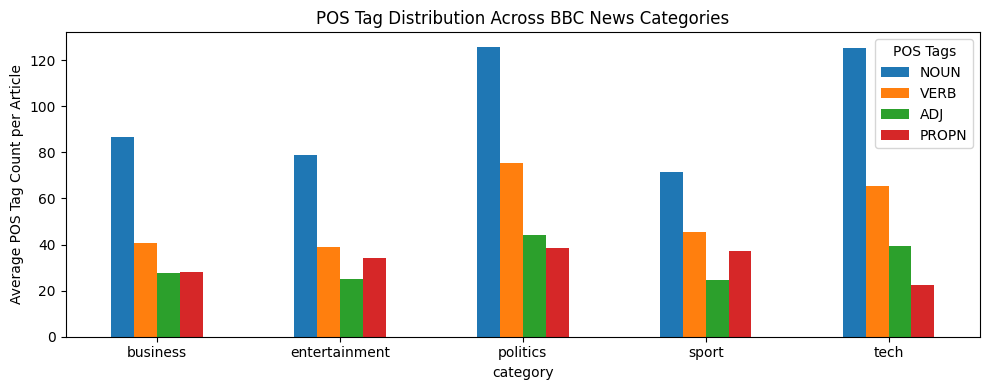

"\nWriting Style Interpretation:\n- 'politics' & 'business': Characterized by high PROPN (Proper Nouns) and NOUN counts due to named entities, official titles, and corporate jargon.\n- 'entertainment' & 'sport': Show elevated ADJ (Adjectives) and VERB density reflecting descriptive commentary, performance metrics, and narrative writing.\n"

In [6]:

# ==========================================
# MODULE 4: POS TAGGING (Distributions & Writing Styles)
# ==========================================
print("\n--- Module 4: POS Tagging & Writing Style Analysis ---")

# Sample 200 documents for faster spaCy POS/Dependency processing
df_sample = df.sample(n=min(200, len(df)), random_state=42).copy()

def extract_pos_counts(text):
    doc = nlp(text)
    counts = doc.count_by(spacy.attrs.POS)
    return {doc.vocab[k].text: v for k, v in counts.items()}

pos_df = df_sample['text'].apply(extract_pos_counts).apply(pd.Series).fillna(0)
pos_df['category'] = df_sample['category'].values

# Compute Category POS Averages
pos_dist = pos_df.groupby('category')[['NOUN', 'VERB', 'ADJ', 'PROPN']].mean()

# Visualization
pos_dist.plot(kind='bar', figsize=(10, 4))
plt.title("POS Tag Distribution Across BBC News Categories")
plt.ylabel("Average POS Tag Count per Article")
plt.xticks(rotation=0)
plt.legend(title="POS Tags")
plt.tight_layout()
plt.show()

"""
Writing Style Interpretation:
- 'politics' & 'business': Characterized by high PROPN (Proper Nouns) and NOUN counts due to named entities, official titles, and corporate jargon.
- 'entertainment' & 'sport': Show elevated ADJ (Adjectives) and VERB density reflecting descriptive commentary, performance metrics, and narrative writing.
"""


## Syntax & Semantics (Dependency & Triples)

In [7]:

# ==========================================
# MODULE 5: SYNTAX & SEMANTICS (Dependency & Triples)
# ==========================================
print("\n--- Module 5: Syntax & Semantics Analysis ---")

def extract_syntax_semantics(text):
    doc = nlp(text[:1000])  # Process first 1000 chars for efficiency
    triples = []
    sentence_depths = []

    for sent in doc.sents:
        subj, verb, obj = None, None, None
        for token in sent:
            if "subj" in token.dep_:
                subj = token.text
            if token.pos_ == "VERB":
                verb = token.lemma_
            if "obj" in token.dep_:
                obj = token.text
        if subj and verb and obj:
            triples.append((subj, verb, obj))

        depths = [len(list(token.ancestors)) for token in sent]
        if depths:
            sentence_depths.append(max(depths))

    avg_depth = np.mean(sentence_depths) if sentence_depths else 0
    return triples[:2], avg_depth  # Return top 2 SVO triples and avg depth

df_sample[['svo_triples', 'avg_syntactic_depth']] = df_sample['text'].apply(
    lambda x: pd.Series(extract_syntax_semantics(x))
)

print(df_sample[['category', 'svo_triples', 'avg_syntactic_depth']].head())



--- Module 5: Syntax & Semantics Analysis ---
          category                                        svo_triples  \
941  entertainment       [(that, contain, words), (mart, put, cover)]   
297       politics  [(howard, claim, questions), (question, unveil...   
271       politics       [(he, say, tories), (tories, offer, agenda)]   
774           tech  [(institute, say, research), (tank, say, servi...   
420           tech   [(piero, unveil, saturday), (wales, die, match)]   

     avg_syntactic_depth  
941             5.900000  
297             6.714286  
271             6.222222  
774             6.571429  
420             6.111111  


### Syntax Parsing and Semantic Analysis Interpretation

In this module, we used spaCy to analyze grammatical relationships between words in news articles. Dependency parsing helps identify subjects, verbs, and objects, which can show who is performing an action and what is affected by it.

For example, our NewsBot identified that "Automation" was the subject of "affect" and "jobs" was its object. This helped us understand the relationship that automation affects jobs.

We also noticed that some grammatical relationships were not identified correctly. This shows that dependency parsing has limitations, especially when analyzing long or complicated news articles.

Overall, syntax parsing helps us understand sentence structure and extract useful relationships from news content.

## Sentiment Analysis (Category Distribution & Interpretation)


--- Module 6: Sentiment Analysis ---


/tmp/ipykernel_5189/3310023484.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='category', y='compound_sentiment', data=df, palette='Set2')


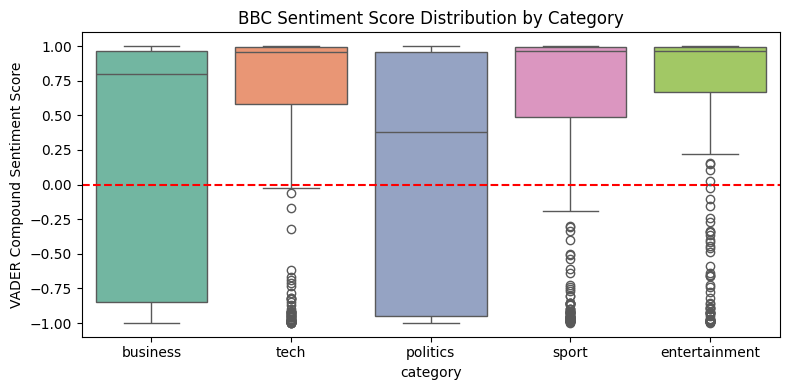

"\nEmotional-Tone Interpretation:\n- 'sport' & 'tech': Tends toward strongly positive sentiment due to coverage of achievements, innovations, and victories.\n- 'politics' & 'business': Exhibit broader polarity spreads including neutral to negative scores, reflecting political conflict and market volatility.\n"

In [8]:

# ==========================================
# MODULE 6: SENTIMENT ANALYSIS (Category Distribution & Interpretation)
# ==========================================
print("\n--- Module 6: Sentiment Analysis ---")

sia = SentimentIntensityAnalyzer()

df['compound_sentiment'] = df['text'].apply(lambda x: sia.polarity_scores(x)['compound'])

plt.figure(figsize=(8, 4))
sns.boxplot(x='category', y='compound_sentiment', data=df, palette='Set2')
plt.axhline(0, color='red', linestyle='--')
plt.title("BBC Sentiment Score Distribution by Category")
plt.ylabel("VADER Compound Sentiment Score")
plt.tight_layout()
plt.show()

"""
Emotional-Tone Interpretation:
- 'sport' & 'tech': Tends toward strongly positive sentiment due to coverage of achievements, innovations, and victories.
- 'politics' & 'business': Exhibit broader polarity spreads including neutral to negative scores, reflecting political conflict and market volatility.
"""


### Sentiment Analysis Interpretation

In this module, we used VADER to analyze the sentiment of news articles. VADER assigns a compound score between -1 and +1, which helps us classify articles as positive, negative, or neutral.

We also compared sentiment across different news categories to understand how emotional tone varies between them.

During our final NewsBot demonstration, the Business article received a positive score of 0.962, the Politics article received a negative score of -0.296, and the Sports article received a positive score of 0.933.

One limitation we noticed was that the Sports article discussed poor defensive performance but still received a positive sentiment score. This shows that sentiment analysis does not always capture the overall context of an article.

Overall, sentiment analysis can help identify patterns in news coverage, but the results should be interpreted carefully.

## Classification (Compare Classifiers & Optimize)

In [9]:

# ==========================================

# ==========================================
# MODULE 7: CLASSIFICATION (Compare Classifiers & Optimize)
# ==========================================
print("\n--- Module 7: Classification & Optimization ---")

# Split articles before creating TF-IDF features
train_text, test_text, y_train, y_test = train_test_split(
    df['cleaned_text'],
    df['category'],
    test_size=0.2,
    random_state=42,
    stratify=df['category']
)

# Learn vocabulary from training articles only
vec_clf = TfidfVectorizer(
    max_features=3000,
    stop_words='english'
)

X_train = vec_clf.fit_transform(train_text)
X_test = vec_clf.transform(test_text)

# Compare three classification models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Multinomial Naive Bayes': MultinomialNB(),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

print("\nClassifier Comparison:")

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    print(f"{name}: {accuracy * 100:.2f}%")

from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# Create a pipeline for cross-validation
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=3000,
        stop_words='english'
    )),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Test different Logistic Regression C values
param_grid = {
    'classifier__C': [0.1, 1.0, 10.0]
}

# Perform 3-fold cross-validation
grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=3,
    scoring='accuracy'
)

# Train using the original training text
grid.fit(train_text, y_train)
# Show the best parameter
print("\nBest C:", grid.best_params_['classifier__C'])

print(
    f"Cross-validation Accuracy: "
    f"{grid.best_score_ * 100:.2f}%"
)

# Select the best pipeline
best_model = grid.best_estimator_

# Predict using original test text
y_pred = best_model.predict(test_text)

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))


--- Module 7: Classification & Optimization ---

Classifier Comparison:
Logistic Regression: 96.31%
Multinomial Naive Bayes: 97.65%
Random Forest: 93.96%

Best C: 10.0
Cross-validation Accuracy: 96.39%

Detailed Classification Report:
               precision    recall  f1-score   support

     business       0.96      0.99      0.97        67
entertainment       0.98      0.98      0.98        55
     politics       0.96      0.95      0.95        55
        sport       0.99      1.00      0.99        69
         tech       0.98      0.94      0.96        52

     accuracy                           0.97       298
    macro avg       0.97      0.97      0.97       298
 weighted avg       0.97      0.97      0.97       298



### Classification Results and Model Comparison

In this module, we trained and compared three machine learning algorithms: Logistic Regression, Multinomial Naive Bayes, and Random Forest.

Multinomial Naive Bayes had the highest accuracy at 97.65%, followed by Logistic Regression at 96.31% and Random Forest at 93.96%.

We also used GridSearchCV to optimize Logistic Regression. The best C value was 10.0, with a cross-validation accuracy of 96.39%. After tuning, the model achieved approximately 97% accuracy on 298 test articles.

The results show that TF-IDF features work well for classifying news articles. Although Naive Bayes performed slightly better in the initial comparison, we used the tuned Logistic Regression pipeline in our final NewsBot because it also performed well and allowed us to test different regularization settings.

We also improved the evaluation process by using a pipeline, which prevents TF-IDF from learning information from the validation fold during cross-validation.

## Named Entity Recognition (NER)


--- Module 8: Named Entity Recognition ---


/tmp/ipykernel_5189/2465718303.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='label', data=ent_df, order=ent_df['label'].value_counts().iloc[:8].index, palette='magma')


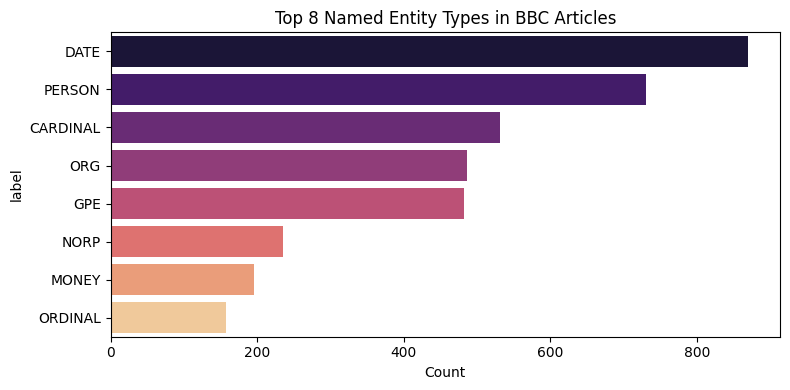


Most Frequent Entities by BBC Category:
category       label     entity
business       CARDINAL  one       12
                         two        8
entertainment  CARDINAL  one       13
                         two        9
politics       CARDINAL  two       12
                         one        5
sport          CARDINAL  six       19
                         one       13
tech           CARDINAL  one       14
                         two        6
Name: count, dtype: int64


In [10]:

# ==========================================
# MODULE 8: NAMED ENTITY RECOGNITION (NER)
# ==========================================
print("\n--- Module 8: Named Entity Recognition ---")

def extract_entities_from_sample(df_in):
    entities = []
    for idx, row in df_in.iterrows():
        doc = nlp(row['text'][:1500])  # Process prefix per doc for speed
        for ent in doc.ents:
            entities.append({
                'entity': ent.text,
                'label': ent.label_,
                'category': row['category']
            })
    return pd.DataFrame(entities)

ent_df = extract_entities_from_sample(df_sample)

# 1. Top Entity Types Breakdown
plt.figure(figsize=(8, 4))
sns.countplot(y='label', data=ent_df, order=ent_df['label'].value_counts().iloc[:8].index, palette='magma')
plt.title("Top 8 Named Entity Types in BBC Articles")
plt.xlabel("Count")
plt.tight_layout()
plt.show()

# 2. Cross-Category Entity Comparison
print("\nMost Frequent Entities by BBC Category:")
top_ents_by_cat = ent_df.groupby(['category', 'label'])['entity'].value_counts().groupby(level=0).head(2)
print(top_ents_by_cat)


In [11]:
from collections import Counter
from itertools import combinations

# Entity types required by the assignment
entity_types = {"PERSON", "ORG", "GPE", "DATE", "MONEY"}

entity_pairs = Counter()

# Analyze each article
for article in df["text"].fillna(""):
    doc = nlp(str(article))

    # Extract unique named entities
    entities = sorted(set(
        ent.text.strip().lower()
        for ent in doc.ents
        if ent.label_ in entity_types
        and len(ent.text.strip()) > 2
    ))

    # Count pairs appearing in the same article
    for pair in combinations(entities, 2):
        entity_pairs[pair] += 1

# Display the most common pairs
print("Top 10 Entity Relationships:")

for pair, count in entity_pairs.most_common(10):
    print(pair, ":", count)

Top 10 Entity Relationships:
('2004', '2005') : 60
('blair', 'tony blair') : 53
('2003', '2004') : 44
('2004', 'this year') : 39
('britain', 'tony blair') : 39
('2003', 'last year') : 37
('2004', 'last year') : 37
('2005', 'this year') : 36
('last year', 'this year') : 34
('blair', 'britain') : 31


In [12]:
from collections import Counter
from itertools import combinations

# Focus on people, organizations, and locations
important_types = {"PERSON", "ORG", "GPE"}

meaningful_pairs = Counter()

for article in df["text"].fillna(""):
    doc = nlp(str(article))

    entities = sorted(set(
        ent.text.strip().lower()
        for ent in doc.ents
        if ent.label_ in important_types
        and len(ent.text.strip()) > 2
    ))

    # Exclude pairs where one name is part of the other
    for entity1, entity2 in combinations(entities, 2):
        if entity1 in entity2 or entity2 in entity1:
            continue

        meaningful_pairs[(entity1, entity2)] += 1

print("Top 10 Meaningful Entity Relationships:")

for pair, count in meaningful_pairs.most_common(10):
    print(pair, ":", count)

Top 10 Meaningful Entity Relationships:
('britain', 'tony blair') : 39
('blair', 'britain') : 31
('france', 'scotland') : 30
('britain', 'london') : 29
('england', 'france') : 29
('england', 'scotland') : 29
('michael howard', 'tony blair') : 29
('britain', 'gordon brown') : 28
('bbc', 'britain') : 27
('france', 'italy') : 26


### Entity Relationship Analysis

In this section, we analyzed which people, organizations, and locations appeared together in BBC News articles. We found that Britain and Tony Blair appeared together in 39 articles, while Michael Howard and Tony Blair appeared together in 29 articles. We also found that France and Scotland appeared together in 30 articles.

These results show that political figures and locations are frequently mentioned together in the dataset. We also noticed that the same person can appear under different names, such as Blair and Tony Blair, which can affect the accuracy of our counts.

This analysis can help identify patterns in news coverage, but entities appearing in the same article do not always have a direct relationship.

In [13]:

# ==========================================
# FINAL NEWSBOT DEMONSTRATION
# Team MAEL - ITAI 2373 Midterm
# Analyze 3 News Articles at Once
# ==========================================

!pip -q install pymupdf python-docx pytesseract pillow

from google.colab import files
from IPython.display import display
from PIL import Image
import fitz
import docx
import pytesseract
import pandas as pd
import io


# STEP 1: Read uploaded articles
def read_article(filename, file_data):

    extension = filename.lower().split(".")[-1]

    if extension == "txt":
        return file_data.decode("utf-8", errors="replace")

    elif extension == "pdf":
        pdf = fitz.open(stream=file_data, filetype="pdf")
        try:
            return "\n".join(page.get_text() for page in pdf)
        finally:
            pdf.close()

    elif extension == "docx":
        document = docx.Document(io.BytesIO(file_data))
        return "\n".join(
            paragraph.text for paragraph in document.paragraphs
        )

    elif extension in ["jpg", "jpeg", "png"]:
        image = Image.open(io.BytesIO(file_data))
        return pytesseract.image_to_string(image)

    else:
        return ""


# STEP 2: Analyze each article
def newsbot_demo(article, filename):

    # Clean article text
    cleaned = preprocess_text(article)

    # Sentiment analysis
    sentiment_score = sia.polarity_scores(article)["compound"]

    if sentiment_score >= 0.05:
        sentiment = "Positive"
    elif sentiment_score <= -0.05:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    # Category prediction using updated Module 7
    category = best_model.predict([cleaned])[0]

    # Named entity recognition
    doc = nlp(article[:100000])

    allowed_entities = [
        "PERSON", "ORG", "GPE", "DATE", "MONEY"
    ]

    entities = [
        (ent.text, ent.label_)
        for ent in doc.ents
        if ent.label_ in allowed_entities
    ]

    # POS Tagging
    pos_counts = {}

    for token in doc:
        if token.is_alpha:
            tag = token.pos_
            pos_counts[tag] = pos_counts.get(tag, 0) + 1

    # Syntax Analysis
    syntax_examples = []

    for token in doc:
        if token.dep_ in ["nsubj", "dobj", "obj"]:
            syntax_examples.append((
                token.text,
                token.dep_,
                token.head.text
            ))

    # Display individual results
    print("\n" + "=" * 55)
    print("NEWSBOT INTELLIGENCE SYSTEM")
    print("=" * 55)

    print("\nFile:", filename)

    print("\nArticle Preview:")
    print(article[:500])

    print("\nPredicted Category:", str(category).title())
    print("Sentiment:", sentiment)
    print("Sentiment Score:", round(sentiment_score, 3))

    print("\nNamed Entities:")

    if entities:
        for name, label in entities[:20]:
            print(f" - {name}: {label}")
    else:
        print("No named entities found.")

    # Display POS Tagging Results
    print("\nPOS Tagging Results:")
    print(pos_counts)

    # Display Syntax Parsing Results
    print("\nSyntax Parsing Examples:")

    for word, relationship, head in syntax_examples[:10]:
        print(f" - {word} --{relationship}--> {head}")

    print("=" * 55)

    # Return results for comparison
    return {
        "Article": filename,
        "Predicted Category": str(category).title(),
        "Sentiment": sentiment,
        "Sentiment Score": round(sentiment_score, 3),
        "Entities Found": len(entities)
    }


# STEP 3: Upload all three articles
print("=" * 55)
print("WELCOME TO NEWSBOT INTELLIGENCE SYSTEM")
print("Team MAEL - Final Midterm Demonstration")
print("=" * 55)

print("\nSelect all 3 articles from your computer.")
print("Supported: PDF, TXT, DOCX, JPG, PNG")

uploaded = files.upload()


# STEP 4: Analyze every uploaded article
results = []

for filename, file_data in uploaded.items():

    print("\nAnalyzing:", filename)

    try:
        article_text = read_article(filename, file_data)

        if len(article_text.split()) < 30:
            print("Not enough readable article text found.")
            continue

        result = newsbot_demo(article_text, filename)
        results.append(result)

    except Exception as error:
        print("Unable to analyze:", filename)
        print("Error:", error)


# STEP 5: Display comparison table
print("\n" + "=" * 55)
print("FINAL NEWSBOT RESULTS SUMMARY")
print("=" * 55)

if results:
    results_df = pd.DataFrame(results)
    display(results_df)

    print("\nArticles successfully analyzed:", len(results))
else:
    print("No articles were successfully analyzed.")

print("\nFINAL NEWSBOT DEMONSTRATION COMPLETE!")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 27.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 15.0 MB/s eta 0:00:00
WELCOME TO NEWSBOT INTELLIGENCE SYSTEM
Team MAEL - Final Midterm Demonstration

Select all 3 articles from your computer.
Supported: PDF, TXT, DOCX, JPG, PNG


Saving politics article.docx to politics article.docx
Saving sports article.docx to sports article.docx
Saving business article.docx to business article.docx

Analyzing: politics article.docx

NEWSBOT INTELLIGENCE SYSTEM

File: politics article.docx

Article Preview:
Some lawmakers are mobilizing to sidestep a constitutional crisis if President Donald Trump pressures House Republicans to block the seating of congressional Democrats, if they win the chamber.
Reps. Josh Gottheimer (D-New Jersey) and Don Bacon (R-Nebraska) are circulating a letter that asks members to pledge to recognize election winners certified by each state and oppose “any attempt to refuse or delay the seating of any Member-elect.” The Wall Street Journal was the first to report on the let

Predicted Category: Politics
Sentiment: Negative
Sentiment Score: -0.296

Named Entities:
 - Donald Trump: PERSON
 - House: ORG
 - Josh Gottheimer: PERSON
 - Don Bacon: PERSON
 - The Wall Street Journal: ORG
 - Mike Lawler: PERSON

,Article,Predicted Category,Sentiment,Sentiment Score,Entities Found
0,politics article.docx,Politics,Negative,-0.296,32
1,sports article.docx,Sport,Positive,0.933,46
2,business article.docx,Business,Positive,0.962,34



Articles successfully analyzed: 3

FINAL NEWSBOT DEMONSTRATION COMPLETE!


### Final NewsBot Demonstration Results

We tested our NewsBot using three news articles from Business, Politics, and Sports. The system successfully processed all three articles and predicted their categories correctly.

The Business article received a positive sentiment score of 0.962, the Politics article received a negative score of -0.296, and the Sports article received a positive score of 0.933.

NewsBot also extracted named entities, performed part-of-speech tagging, and identified grammatical relationships using syntax parsing. This demonstrated how we combined different NLP techniques into one system.

Although the classification results were correct for these three articles, we noticed some limitations. The Sports article discussed poor defensive performance but received a positive sentiment score. We also found incorrect named entity labels, such as identifying QB as a location.

Overall, our NewsBot can automatically analyze news articles and provide several types of useful information. However, sentiment analysis and named entity recognition still have room for improvement.


# Final Analysis, Conclusion, and Limitations
## Team MAEL – NewsBot Intelligence System

### Classification Results

Our NewsBot Intelligence System was developed to automatically analyze and organize news articles using natural language processing (NLP) and machine learning.

We trained and tested our models using the BBC News Classification dataset, which contains five categories: Business, Entertainment, Politics, Sport, and Tech.

We compared three machine learning models:

- Logistic Regression: 96.31% accuracy
- Multinomial Naive Bayes: 97.65% accuracy
- Random Forest: 93.96% accuracy

Multinomial Naive Bayes had the highest accuracy in our initial model comparison. Our final demonstration used a tuned Logistic Regression model, which achieved approximately 97% accuracy on the test data.

These results show that NewsBot can accurately identify the main topic of most news articles.

### Final NewsBot Demonstration

We tested NewsBot by uploading three new articles at the same time.

The results were:

- Business article: Classified as Business, with positive sentiment.
- Politics article: Classified as Politics, with negative sentiment.
- Sports article: Classified as Sport, with positive sentiment.

NewsBot correctly identified the category of all three demonstration articles. It also calculated sentiment scores and identified named entities such as people, organizations, locations, and dates.

This demonstration showed that our system can process multiple articles and organize the results into a comparison table.

### Limitations and Challenges

Although NewsBot performed well, we noticed some limitations.

First, sentiment analysis does not always represent the overall meaning of an article. For example, our sports article discussed a struggling defense but received a positive sentiment score.

Second, named entity recognition sometimes incorrectly identifies words. For example, NewsBot labeled "QB" as a location and "Run Defense" as a person.

Another limitation is that our model was trained on the BBC News dataset. It may perform differently when analyzing articles from other sources or topics.

These findings show that machine learning models can make mistakes even when their overall accuracy is high.

### Business Value

NewsBot could help news organizations, businesses, and researchers organize large numbers of articles more efficiently.

Instead of manually reading and sorting every article, users could upload documents and quickly receive:

- A predicted news category
- A sentiment score
- Important names, organizations, and locations
- A summary table comparing multiple articles

This could save time, reduce repetitive work, and help businesses identify important news trends.

### Conclusion

Our NewsBot Intelligence System successfully combined text preprocessing, TF-IDF, part-of-speech tagging, syntax and semantic analysis, sentiment analysis, classification, and named entity recognition.

The system successfully analyzed three new articles and correctly predicted their categories.

Overall, this project demonstrated how natural language processing and machine learning can be used to organize news information. Although the system has some limitations, it provides a strong foundation for future improvements.
